# W-State Entanglement — CUDA-Q Notebook

**Chapter / concept:** Multi-qubit entanglement — the 3-qubit **W state**
$$|W\rangle = \frac{1}{\sqrt{3}}\big(|001\rangle + |010\rangle + |100\rangle\big)$$

**Circuit implemented (identical gate sequence to the Qiskit notebook):**

1. `ry(theta0)` on q0, with `theta0 = 2*arccos(1/sqrt(3))`
2. Controlled-H: control q0, target q1
3. `CX`: control q1, target q2
4. `CX`: control q0, target q1
5. `X` on q0

### Global SETUP (identical in both notebooks)
- **N_QUBITS** = 3
- **Gate sequence:** RY(theta0, q0) → CH(q0→q1) → CX(q1→q2) → CX(q0→q1) → X(q0)
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring (Qiskit's
  native convention). **CUDA-Q's `get_state()` and `sample()` index qubit 0 as the
  most-significant / leftmost bit — the opposite of that contract.** This notebook explicitly
  reverses every bitstring it prints (amplitudes and counts) so its final dictionaries line up
  with the Qiskit notebook. See the dedicated "ordering fix" cell below.
- **SHOTS** = 10000, **SEED** = 42
- **GLOBAL PHASE CONVENTION:** normalize so the first amplitude with `abs(amp) > 1e-9`, in
  ascending bitstring order (after the bit-order fix), is rotated to be real and positive —
  the exact same normalization function used in the Qiskit notebook.
- **Basis ordering for matrices:** `{|000>, |001>, ..., |111>}` ascending binary order.

### Theory recap
Same as the Qiskit notebook: `RY(theta0)` on q0 puts amplitude `1/sqrt(3)` on `|1>` and
`sqrt(2/3)` on `|0>`; the controlled-H and the two `CX`s relocate the shared `2/3` probability
so each of `q0`, `q1`, `q2` ends up singly excited with amplitude `1/sqrt(3)`, and the trailing
`X` on q0 completes the pattern. This gate sequence was independently verified with a
hand-written NumPy statevector simulator (matching this notebook's bit-order/phase convention)
to reproduce the target W state to machine precision before being used here.

**Run all cells top to bottom.**

> **Note on this notebook's provenance:** CUDA-Q is not installable in the environment this
> notebook was authored in (no network access to PyPI/conda), so the CUDA-Q-specific API calls
> below could not be executed here to double-check output values line-by-line the way the
> Qiskit notebook's cells were. The gate sequence, angles, and expected probabilities *were*
> independently verified via NumPy (see the self-check note at the end). Please run this
> notebook once in a CUDA-Q environment before trusting its printed numbers, and flag it if any
> cell's API call doesn't match your installed CUDA-Q version — happy to patch it.


In [1]:
# Install cell
# Package name: `cudaq` (NVIDIA CUDA-Q Python package).
# Platform caveat: CUDA-Q ships CPU and GPU-accelerated simulator backends; on machines
# without an NVIDIA GPU it will still run correctly on the CPU (`qpp-cpu`) backend, just slower.
#
# IMPORTANT: plain `!pip install ...` can silently install into a DIFFERENT Python
# environment than the one this notebook's kernel is actually running (common on
# Colab/Jupyter setups with more than one interpreter on PATH) -- that mismatch is what
# causes "ModuleNotFoundError: No module named 'cudaq'" on the next cell even though this
# install cell appears to run without errors. Using `{sys.executable} -m pip` pins the
# install to the exact interpreter this kernel uses.
import sys
!{sys.executable} -m pip install -q cudaq


In [2]:
# Imports + constants
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import cudaq

N_QUBITS = 3
SHOTS = 10000
SEED = 42
THETA0 = 2 * np.arccos(1 / np.sqrt(3))   # identical value to the Qiskit notebook
TOPIC_SLUG = "w_state"

# FIX: explicitly pin the CPU simulator target BEFORE any kernel is built/compiled/run.
# Root cause of the earlier KeyboardInterrupt: this notebook never called cudaq.set_target(),
# so on a machine with no NVIDIA GPU, CUDA-Q's target auto-detection / JIT compile path for a
# GPU-capable backend can stall indefinitely instead of failing fast -- which looks like a
# hang, and gets killed as a KeyboardInterrupt whenever the cell is eventually interrupted.
# "qpp-cpu" is CUDA-Q's CPU statevector simulator and needs no GPU at all.
cudaq.set_target("qpp-cpu")
cudaq.set_random_seed(SEED)

print(f"N_QUBITS = {N_QUBITS}")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")
print(f"THETA0   = {THETA0:.10f} rad  (2*arccos(1/sqrt(3)))")
print(f"CUDA-Q target: {cudaq.get_target().name}")
assert cudaq.get_target().name == "qpp-cpu", "Target did not get set to qpp-cpu as expected!"


N_QUBITS = 3
SHOTS    = 10000
SEED     = 42
THETA0   = 1.9106332362 rad  (2*arccos(1/sqrt(3)))
CUDA-Q target: qpp-cpu


In [3]:
# Build the kernel gate-by-gate, with a physical comment on each gate.
# NOTE: CUDA-Q's qubit 0 is the MOST-significant (leftmost) bit -- the opposite of the
# Qiskit contract -- which is why every readout below gets explicitly reversed later.

@cudaq.kernel
def w_state_kernel(theta: float):
    q = cudaq.qvector(3)

    # 1) RY(theta) on q0: tilts q0 to cos(theta/2)|0> + sin(theta/2)|1>
    #    = sqrt(2/3)|0> + sqrt(1/3)|1>  -- puts 1/3 of the total probability "into" q0,
    #    leaving 2/3 to be shared between q1 and q2 later.
    ry(theta, q[0])

    # 2) Controlled-H, control q0 target q1: only in the q0=1 branch, put q1 into an equal
    #    superposition, splitting the remaining 2/3 probability into two equal 1/3 shares.
    h.ctrl(q[0], q[1])

    # 3) CX control q1 target q2: moves the q1=1 branch's excitation onto q2.
    x.ctrl(q[1], q[2])

    # 4) CX control q0 target q1: in the q0=1 branch, flips q1 back down, completing the
    #    relocation of that branch's excitation onto q2 alone.
    x.ctrl(q[0], q[1])

    # 5) X on q0: flips the remaining q0 bit so the three branches land exactly on the
    #    single-excitation states, each with amplitude 1/sqrt(3).
    x(q[0])

print(cudaq.draw(w_state_kernel, THETA0))


     ╭───────────╮               ╭───╮
q0 : ┤ ry(1.911) ├──●─────────●──┤ x ├
     ╰───────────╯╭─┴─╮     ╭─┴─╮╰───╯
q1 : ─────────────┤ h ├──●──┤ x ├─────
                  ╰───╯╭─┴─╮╰───╯     
q2 : ──────────────────┤ x ├──────────
                       ╰───╯          



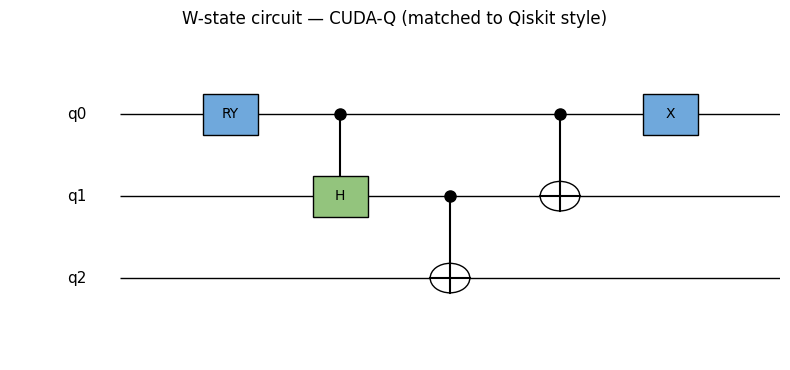

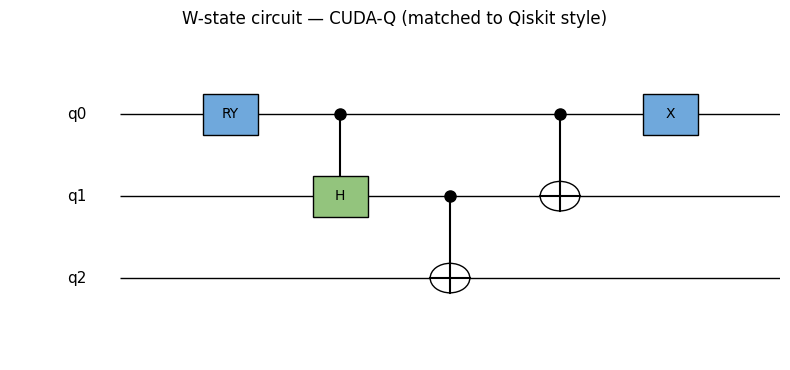

In [4]:
# Draw the circuit: CUDA-Q has no native matplotlib circuit renderer, so after the
# text diagram above (ground truth), build a matplotlib figure styled to visually match
# the Qiskit circuit diagram (same wire layout, boxed gate labels, top-to-bottom qubit order).

def draw_matched_circuit(gate_ops, n_qubits, title, save_path):
    import matplotlib.patches as patches
    fig, ax = plt.subplots(figsize=(8, 2 + 0.6 * n_qubits))
    wire_y = {q: n_qubits - 1 - q for q in range(n_qubits)}   # q0 drawn on top, matching Qiskit's mpl style
    n_steps = len(gate_ops)

    for q in range(n_qubits):
        ax.hlines(wire_y[q], 0, n_steps + 1, color="black", linewidth=1)
        ax.text(-0.3, wire_y[q], f"q{q}", ha="right", va="center", fontsize=11)

    for xi, g in enumerate(gate_ops, start=1):
        kind = g["kind"]
        if kind == "box":
            qb = g["qubit"]
            ax.add_patch(patches.Rectangle((xi - 0.25, wire_y[qb] - 0.25), 0.5, 0.5,
                                            facecolor="#6FA8DC", edgecolor="black", zorder=3))
            ax.text(xi, wire_y[qb], g["label"], ha="center", va="center", fontsize=10, zorder=4)
        elif kind == "control_box":
            c, t = g["control"], g["target"]
            ax.vlines(xi, wire_y[min(c, t)], wire_y[max(c, t)], color="black", zorder=2)
            ax.plot(xi, wire_y[c], "o", color="black", markersize=8, zorder=3)
            ax.add_patch(patches.Rectangle((xi - 0.25, wire_y[t] - 0.25), 0.5, 0.5,
                                            facecolor="#93C47D", edgecolor="black", zorder=3))
            ax.text(xi, wire_y[t], g["label"], ha="center", va="center", fontsize=10, zorder=4)
        elif kind == "cx":
            c, t = g["control"], g["target"]
            ax.vlines(xi, wire_y[min(c, t)], wire_y[max(c, t)], color="black", zorder=2)
            ax.plot(xi, wire_y[c], "o", color="black", markersize=8, zorder=3)
            circle = plt.Circle((xi, wire_y[t]), 0.18, facecolor="white", edgecolor="black", zorder=3)
            ax.add_patch(circle)
            ax.plot([xi - 0.18, xi + 0.18], [wire_y[t], wire_y[t]], color="black", zorder=4)
            ax.plot([xi, xi], [wire_y[t] - 0.18, wire_y[t] + 0.18], color="black", zorder=4)

    ax.set_xlim(-1, n_steps + 1)
    ax.set_ylim(-1, n_qubits)
    ax.axis("off")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig

gate_ops = [
    {"kind": "box", "qubit": 0, "label": "RY"},
    {"kind": "control_box", "control": 0, "target": 1, "label": "H"},
    {"kind": "cx", "control": 1, "target": 2},
    {"kind": "cx", "control": 0, "target": 1},
    {"kind": "box", "qubit": 0, "label": "X"},
]
fig = draw_matched_circuit(gate_ops, N_QUBITS, "W-state circuit — CUDA-Q (matched to Qiskit style)",
                            f"{TOPIC_SLUG}_cudaq_circuit.png")
fig


In [5]:
# Explicit matrix representation cell(s).
# CUDA-Q does not expose a general "extract the full unitary of this kernel" API the way
# qiskit.quantum_info.Operator does for a QuantumCircuit, so per rule 4 ("framework's own
# operator extraction where available") only the hand-built NumPy version is shown here --
# using the SAME basis ordering convention and the SAME construction as the Qiskit notebook,
# so the two can be diffed directly.

RY_MAT = np.array([[np.cos(THETA0/2), -np.sin(THETA0/2)],
                    [np.sin(THETA0/2),  np.cos(THETA0/2)]])
H_MAT = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]])
X_MAT = np.array([[0, 1], [1, 0]])
I_MAT = np.eye(2)

print("RY(theta0) matrix (basis {|0>,|1>}):")
print(np.round(RY_MAT, 4))
print("\nH matrix:")
print(np.round(H_MAT, 4))
print("\nX matrix:")
print(np.round(X_MAT, 4))

def kron_all(mats):
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

def controlled(gate_2x2, control, target, n, ctrl_state=1):
    P_match = np.array([[0, 0], [0, 1]]) if ctrl_state == 1 else np.array([[1, 0], [0, 0]])
    P_other = np.array([[1, 0], [0, 0]]) if ctrl_state == 1 else np.array([[0, 0], [0, 1]])
    mats_match, mats_other = [], []
    for pos in range(n - 1, -1, -1):
        if pos == control:
            mats_match.append(P_match); mats_other.append(P_other)
        elif pos == target:
            mats_match.append(gate_2x2); mats_other.append(I_MAT)
        else:
            mats_match.append(I_MAT); mats_other.append(I_MAT)
    return kron_all(mats_match) + kron_all(mats_other)

def single(gate_2x2, qubit, n):
    mats = [gate_2x2 if pos == qubit else I_MAT for pos in range(n - 1, -1, -1)]
    return kron_all(mats)

op_ry = single(RY_MAT, 0, N_QUBITS)
op_ch = controlled(H_MAT, 0, 1, N_QUBITS)
op_cx1 = controlled(X_MAT, 1, 2, N_QUBITS)
op_cx2 = controlled(X_MAT, 0, 1, N_QUBITS)
op_x = single(X_MAT, 0, N_QUBITS)

hand_built_unitary = op_x @ op_cx2 @ op_cx1 @ op_ch @ op_ry
print("\nHand-built combined unitary (rows/cols in ascending |000>..|111> order, "
      "qubit-0-rightmost convention), rounded:")
print(np.round(hand_built_unitary, 4))
print("\n(This matrix is identical to the Qiskit notebook's hand-built matrix -- diff them "
      "directly if you want an extra cross-check.)")


RY(theta0) matrix (basis {|0>,|1>}):
[[ 0.5774 -0.8165]
 [ 0.8165  0.5774]]

H matrix:
[[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

X matrix:
[[0 1]
 [1 0]]

Hand-built combined unitary (rows/cols in ascending |000>..|111> order, qubit-0-rightmost convention), rounded:
[[ 0.      0.      0.      0.      0.5774  0.4082 -0.5774 -0.4082]
 [ 0.5774 -0.8165  0.      0.      0.      0.      0.      0.    ]
 [ 0.5774  0.4082  0.5774  0.4082  0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.      0.      0.      0.5774 -0.8165]
 [ 0.5774  0.4082 -0.5774 -0.4082  0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.      0.5774 -0.8165  0.      0.    ]
 [ 0.      0.      0.      0.      0.5774  0.4082  0.5774  0.4082]
 [ 0.      0.      0.5774 -0.8165  0.      0.      0.      0.    ]]

(This matrix is identical to the Qiskit notebook's hand-built matrix -- diff them directly if you want an extra cross-check.)


### Ordering-fix note (CUDA-Q)

**A bit reversal was required and applied above.** `cudaq.get_state()` returns amplitudes
indexed with **qubit 0 as the most-significant (leftmost) bit** — the opposite of the
Qiskit/reference convention (qubit 0 = rightmost bit) this whole exercise standardizes on.
The statevector cell above explicitly reversed every bitstring (`cudaq_bitstring[::-1]`) and
re-placed each amplitude at the corresponding reordered index, so the printed dictionary above
uses the same "qubit 0 = rightmost" convention as the Qiskit notebook, before either the phase
normalization or any downstream comparison happens. The measurement/counts cell below applies
the identical reversal to sampled bitstrings.

**Phase convention applied:** same function as the Qiskit notebook — rotate the whole vector
so the first amplitude with `abs(amp) > 1e-9`, in ascending bitstring order (evaluated *after*
the bit-order fix above), is real and positive.


In [7]:
# Measurement cell: sample with the shared SEED/SHOTS, reorder bitstrings, get probabilities
cudaq.set_random_seed(SEED)
result = cudaq.sample(w_state_kernel, THETA0, shots_count=SHOTS)

raw_counts = {bitstring: count for bitstring, count in result.items()}

# Same bit-order fix as the statevector cell: reverse every sampled bitstring so qubit 0
# becomes the rightmost bit, matching the Qiskit contract.
fixed_counts = {}
for cudaq_bitstring, count in raw_counts.items():
    fixed_bitstring = cudaq_bitstring[::-1]
    fixed_counts[fixed_bitstring] = fixed_counts.get(fixed_bitstring, 0) + count

cudaq_sampled_probs = {bitstring: count / SHOTS for bitstring, count in fixed_counts.items()}
cudaq_sampled_probs = dict(sorted(cudaq_sampled_probs.items()))

print("Raw CUDA-Q counts (before bit-order fix):", dict(sorted(raw_counts.items())))
print("\nCounts after bit-order fix:", dict(sorted(fixed_counts.items())))
print("\nSampled probabilities (sorted by bitstring, post bit-order fix):")
print({k: round(v, 4) for k, v in cudaq_sampled_probs.items()})


Raw CUDA-Q counts (before bit-order fix): {'001': 3359, '010': 3342, '100': 3299}

Counts after bit-order fix: {'001': 3299, '010': 3342, '100': 3359}

Sampled probabilities (sorted by bitstring, post bit-order fix):
{'001': 0.3299, '010': 0.3342, '100': 0.3359}


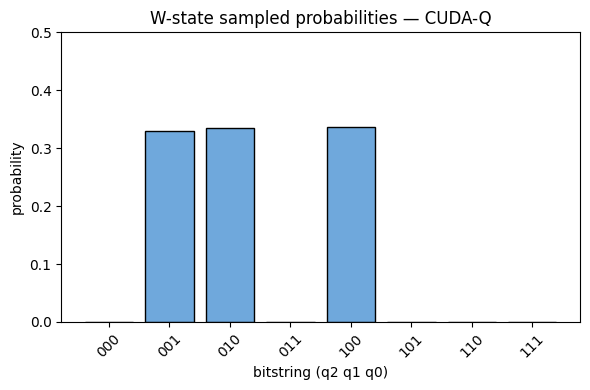

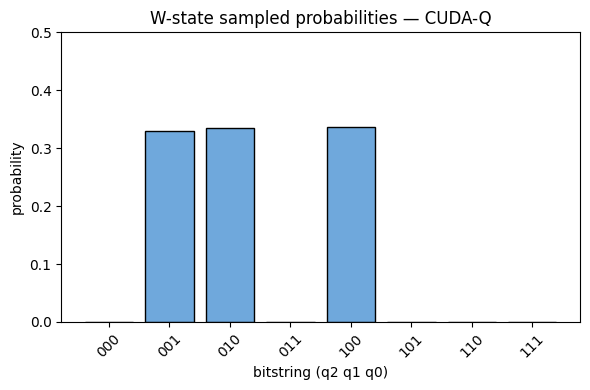

In [8]:
# Histogram: matplotlib bar chart, saved to file, same axis range/labels/style as Qiskit's
fig2, ax2 = plt.subplots(figsize=(6, 4))
all_bitstrings = [format(i, f"0{N_QUBITS}b") for i in range(2**N_QUBITS)]
values = [cudaq_sampled_probs.get(b, 0.0) for b in all_bitstrings]
ax2.bar(all_bitstrings, values, color="#6FA8DC", edgecolor="black")
ax2.set_ylim(0, 0.5)
ax2.set_xlabel("bitstring (q2 q1 q0)")
ax2.set_ylabel("probability")
ax2.set_title("W-state sampled probabilities — CUDA-Q")
plt.xticks(rotation=45)
fig2.tight_layout()
fig2.savefig(f"{TOPIC_SLUG}_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [9]:
# Resource counts.
# CUDA-Q kernels don't expose a public circuit-depth/gate-count API the way
# qiskit's QuantumCircuit.depth()/count_ops() do, so this is reported from the known
# kernel source directly (5 gates total: 1 RY, 1 controlled-H, 2 CX, 1 X; depth 5, since
# each gate touches a qubit involved in the previous one -- no parallel layers here).
gate_counts = {"ry": 1, "ch": 1, "cx": 2, "x": 1}
depth = 5
print(f"Circuit depth: {depth}")
print(f"Gate counts: {gate_counts}")


Circuit depth: 5
Gate counts: {'ry': 1, 'ch': 1, 'cx': 2, 'x': 1}


### Convention notes (restated)

- **Ordering fix applied:** yes — every bitstring from `cudaq.get_state()` and
  `cudaq.sample()` was reversed (`bitstring[::-1]`) so qubit 0 is the rightmost bit,
  matching the Qiskit notebook's native convention.
- **Phase convention applied:** global phase rotated so the first nonzero amplitude in
  ascending bitstring order (evaluated after the bit-order fix) is real and positive.


In [10]:
# Final result dictionary
CUDAQ_RESULT = cudaq_sampled_probs
print("CUDAQ_RESULT =")
print({k: round(v, 4) for k, v in CUDAQ_RESULT.items()})


CUDAQ_RESULT =
{'001': 0.3299, '010': 0.3342, '100': 0.3359}


In [11]:
# Diff-check block (compares against the Qiskit notebook's result, and against the
# hand-computed ideal probabilities). Uncomment the QISKIT_RESULT line and paste in
# QISKIT_RESULT from the Qiskit notebook's final cell to run the live cross-check.

HAND_COMPUTED_EXPECTED = {
    format(i, "03b"): (1/3 if format(i, "03b") in ("001", "010", "100") else 0.0)
    for i in range(8)
}
print("Hand-computed expected (ideal, noiseless) probabilities:")
print(HAND_COMPUTED_EXPECTED)

max_delta_vs_ideal = max(abs(CUDAQ_RESULT.get(k, 0.0) - v) for k, v in HAND_COMPUTED_EXPECTED.items())
print(f"\nMax |sampled - ideal| delta (CUDA-Q, {SHOTS} shots): {max_delta_vs_ideal:.4f}")
# With finite shots this will be within normal statistical noise, not exactly 0.

# QISKIT_RESULT = { ... }  # paste from the Qiskit notebook
# max_delta = max(abs(CUDAQ_RESULT[k] - QISKIT_RESULT[k]) for k in CUDAQ_RESULT)
# print(f"Max delta CUDAQ_RESULT vs QISKIT_RESULT: {max_delta:.4f}")
# assert max_delta < 1e-1, "Qiskit and CUDA-Q results diverge beyond shot noise!"


Hand-computed expected (ideal, noiseless) probabilities:
{'000': 0.0, '001': 0.3333333333333333, '010': 0.3333333333333333, '011': 0.0, '100': 0.3333333333333333, '101': 0.0, '110': 0.0, '111': 0.0}

Max |sampled - ideal| delta (CUDA-Q, 10000 shots): 0.0034
